# **딥러닝 기초 : 회귀**

In [40]:
from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.model_selection import train_test_split   #---- 문제답 분리


import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)
    
from keras.models import Sequential
from keras.layers import Dense, Flatten

In [2]:
df = pd.read_csv("../datas/BostonHousing.csv")
df.head(2)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.9,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.9,9.14,21.6


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [4]:
y = df['medv']
X = df.drop(columns=["medv"])
X_train7, X_test3,    y_train7, y_test3 = train_test_split( X, y, test_size=0.3, random_state=1234)

* LinearRegression() mse 1차 점수 : 4.9105
* LinearRegression() mse outlier : 4.4170
* Ridge L2 규제 적용 mse : 4.2175

In [5]:
#Dense?

In [6]:
df.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'medv'],
      dtype='str')

In [7]:
model = Sequential([
                Dense(units=16,  activation='relu', input_dim=13),
                Dense(units=18,  activation='relu'),
                Dense(units=20,  activation='relu'),
                Dense(units=8,   activation='relu'),
                Dense(units=1)
        ])
model.compile(loss="mse" , optimizer="adam",  metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')] )

C:\IT\python_workspace\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 18)                  │             306 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 20)                  │             380 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,087 (4.25 KB)

 Trainable params: 1,087 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
fit_res = model.fit(X_train7, y_train7, batch_size=4, epochs=20
                    , validation_data=(X_test3, y_test3) )

Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1268.5941 - rmse: 35.6173 - val_loss: 121.3778 - val_rmse: 11.0172
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 92.0708 - rmse: 9.5954 - val_loss: 92.9739 - val_rmse: 9.6423
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 80.8924 - rmse: 8.9940 - val_loss: 84.8946 - val_rmse: 9.2138
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 76.5046 - rmse: 8.7467 - val_loss: 80.2780 - val_rmse: 8.9598
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 74.9104 - rmse: 8.6551 - val_loss: 76.4092 - val_rmse: 8.7412
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 73.7952 - rmse: 8.5904 - val_loss: 73.6344 - val_rmse: 8.5810
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 72.3736 - rmse: 8.5073 - val_loss: 72.4292 - val_rmse: 8.5105
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 71.1988 - rmse: 8.4379 - val_loss: 71.1370 - val_rmse: 8.4343
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━

In [10]:
# loss: 28.4466 - rmse: 5.3335 - val_loss: 37.3233 - val_rmse: 6.1093
fit_res.history['loss'][:2]  , fit_res.history['val_rmse'][:2]

([1268.5941162109375, 92.07080078125], [11.017159461975098, 9.642295837402344])

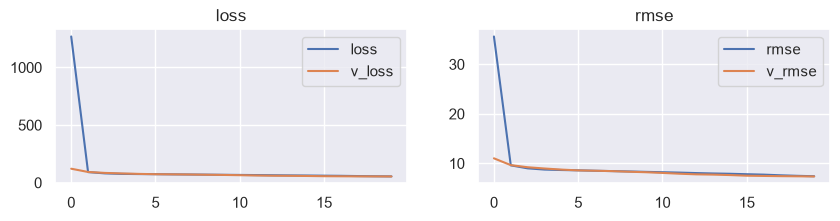

In [11]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['rmse']   ,   label="rmse")
ax2.plot(fit_res.history['val_rmse'],  label="v_rmse")
ax2.legend()
ax2.set_title("rmse")

plt.show()

In [12]:
res = model.evaluate(X_test3, y_test3)
print( f"rmse : {res[1]:.4f} ")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 54.0686 - rmse: 7.3531 
rmse : 7.3531 


# **딥러닝 기초 : 분류**

In [13]:
df = pd.read_csv("../datas/pima/train.csv") 
df.columns = df.columns.str.lower()
df = df.rename(columns={'bloodpressure':'blood',
                              'skinthickness' : 'skin',
                              'diabetespedigreefunction': 'diabet'})
df.head(2)

,pregnancies,glucose,blood,skin,insulin,bmi,diabet,age,outcome
0,2,90,60,0,0,23.5,0.191,25,0
1,2,92,52,0,0,30.1,0.141,22,0


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  616 non-null    int64  
 1   glucose      616 non-null    int64  
 2   blood        616 non-null    int64  
 3   skin         616 non-null    int64  
 4   insulin      616 non-null    int64  
 5   bmi          616 non-null    float64
 6   diabet       616 non-null    float64
 7   age          616 non-null    int64  
 8   outcome      616 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 43.4 KB


In [15]:
y = df['outcome']
X = df.drop(columns=["outcome"])
X_train7, X_test3,    y_train7, y_test3 = train_test_split( X, y, test_size=0.3, random_state=1234)

In [16]:
X.columns

Index(['pregnancies', 'glucose', 'blood', 'skin', 'insulin', 'bmi', 'diabet',
       'age'],
      dtype='str')

In [17]:
model = Sequential([
                Dense(units=16,  activation='relu', input_dim=8),
                Dense(units=18,  activation='relu'),
                Dense(units=20,  activation='relu'),
                Dense(units=8,   activation='relu'),
                Dense(units=1,   activation='sigmoid')
        ])
model.compile(loss="binary_crossentropy" , optimizer="adam",  metrics=[tf.keras.metrics.F1Score(average='micro', threshold=0.5, name='f1_score')] )

C:\IT\python_workspace\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 18)                  │             306 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 20)                  │             380 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 8)                   │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,007 (3.93 KB)

 Trainable params: 1,007 (3.93 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
fit_res = model.fit(X_train7, y_train7, batch_size=4, epochs=30, validation_data=(X_test3, y_test3) )

Epoch 1/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - f1_score: 0.2412 - loss: 3.3425 - val_f1_score: 0.2105 - val_loss: 0.7809
Epoch 2/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.3226 - loss: 0.7315 - val_f1_score: 0.1944 - val_loss: 0.7058
Epoch 3/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.4128 - loss: 0.6409 - val_f1_score: 0.2105 - val_loss: 0.6850
Epoch 4/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.3850 - loss: 0.6167 - val_f1_score: 0.2105 - val_loss: 0.6679
Epoch 5/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.4352 - loss: 0.5994 - val_f1_score: 0.1867 - val_loss: 0.6635
Epoch 6/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.4486 - loss: 0.5858 - val_f1_score: 0.1918 - val_loss: 0.6628
Epoch 7/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.4434 - loss: 0.5778 - val_f1_score: 0.1667 - val_loss: 0.6735
Epoch 8/30
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - f1_score: 0.4265 - loss: 0.5818 - val_f1_score: 0.

In [20]:
res = model.evaluate(X_test3, y_test3)
print(f"f1_score : {res[1]:.4f} ")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.3077 - loss: 0.6324 
f1_score : 0.3077 


# **딥러닝 기초 : 이미지 분석**
* https://keras.io/api/datasets/fashion_mnist/

<pre>
0	T-shirt/top
1	Trouser
2	Pullover
3	Dress
4	Coat
5	Sandal
6	Shirt
7	Sneaker
8	Bag
9	Ankle boot

In [21]:
from keras.datasets.fashion_mnist import load_data

In [22]:
(X_train, y_train), (X_test, y_test) = load_data()

In [23]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(60000, 28, 28) (10000, 28, 28) (60000,) (10000,)


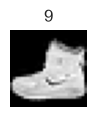

In [24]:
#x_train[0]
plt.figure(figsize=(1, 1))
plt.imshow(X_train[0], cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.title(f"{y_train[0]}")
plt.show()


In [25]:
LABEL_NAME__ = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

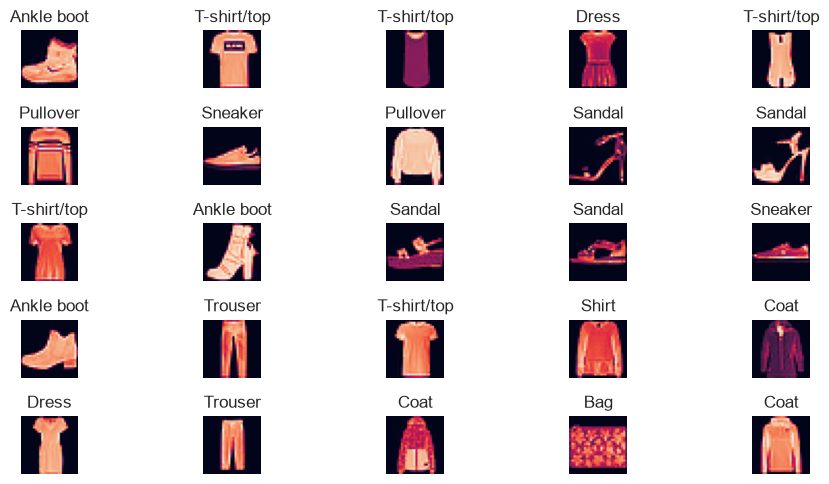

In [26]:
plt.figure(figsize=(10,5))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.grid(False)
    plt.axis('off')
    plt.imshow(X_train[i])
    plt.title(LABEL_NAME__[y_train[i]])
plt.tight_layout()    
plt.show()

* **MinMaxScaler**

In [27]:
X_train = X_train / 255.0
X_test  = X_test / 255.0

In [28]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [29]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [35]:
28 * 28

784

In [41]:
model = Sequential([
                #CNN
                Flatten(input_shape=(28,28) ), 
                Dense(units=280, activation='relu'),
                Dense(units=160, activation='relu'),
                Dense(units=80,  activation='relu'),
                Dense(units=120, activation='relu'),
                Dense(units=80,  activation='relu'),
                Dense(units=60,  activation='relu'),
                Dense(units=20,  activation='relu'),
                Dense(units=10,  activation='softmax')
        ])
model.compile(loss="sparse_categorical_crossentropy" , optimizer="adam",  metrics=['accuracy'] )

C:\IT\python_workspace\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [37]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                     │ (None, 280)                 │         219,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 160)                 │          44,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 80)                  │          12,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 120)                 │           9,720 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 80)                  │           9,680 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 60)                  │           4,860 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 20)                  │           1,220 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 10)                  │             210 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 303,330 (1.16 MB)

 Trainable params: 303,330 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
X_test.shape, y_test.shape

((10000, 28, 28), (10000,))

In [42]:
fit_res = model.fit(X_train, y_train, batch_size=256, epochs=20, validation_data=(X_test, y_test) )

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7630 - loss: 0.6714 - val_accuracy: 0.8180 - val_loss: 0.4948
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8521 - loss: 0.4091 - val_accuracy: 0.8503 - val_loss: 0.4018
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8684 - loss: 0.3576 - val_accuracy: 0.8568 - val_loss: 0.3872
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8794 - loss: 0.3268 - val_accuracy: 0.8640 - val_loss: 0.3735
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8852 - loss: 0.3098 - val_accuracy: 0.8753 - val_loss: 0.3460
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8914 - loss: 0.2937 - val_accuracy: 0.8643 - val_loss: 0.3752
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8955 - loss: 0.2791 - val_accuracy: 0.8721 - val_loss: 0.3590
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9014 - loss: 0.2647 - val_accuracy: 0.

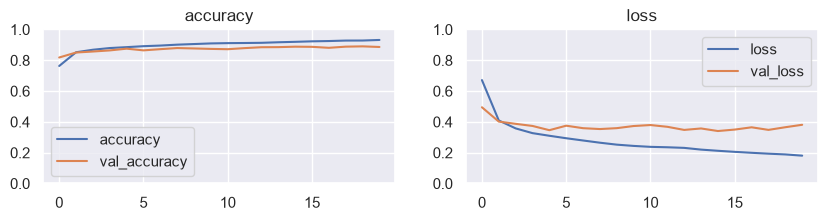

In [45]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['accuracy']   ,   label="accuracy")
ax1.plot(fit_res.history['val_accuracy'],  label="val_accuracy")
ax1.legend()
ax1.set_ylim(0, 1.0)
ax1.set_title("accuracy")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['loss']   ,   label="loss")
ax2.plot(fit_res.history['val_loss'],  label="val_loss")
ax2.legend()
ax2.set_ylim(0, 1.0)
ax2.set_title("loss")

plt.show()


In [48]:
res = model.evaluate(X_test, y_test)
print(f"accuracy : {res[1]:.4f} ")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8863 - loss: 0.3811
accuracy : 0.8863 
